# Compare the position effect on the validation plates with the screen

This notebook puts the validation plates next to the screen, with the same measurements on both, to show why the plate-position correction removed most of the position effect in the screen and only part of it on the validation plates.
It changes no data: it reads the well medians and the fit of this step (`1.fit_position_correction.ipynb`) and of the screen (`4.image_based_profiling/3a.position_correction`).

1. **Variance by principal component, split into position and heart status.** The principal components of the well profiles, with the part that is associated with plate position (row plus column, in red; row alone, in orange) and the part that is associated with the heart status of the cells (non-failing against failing, in blue), before and after the correction. The parts overlap: they are associations and do not add up.
2. **Survival of the non-failing against failing difference.** The length of the difference between the non-failing and the failing DMSO profile on every plate, before and after the correction.
3. **Compound placement in the screen.** Whether the position of a compound on the screen platemaps is independent of the compound.

**Input**

- `well_medians.parquet` and `position_correction_fit.npz` of this folder (validation plates)
- `../../../4.image_based_profiling/3a.position_correction/well_medians.parquet` and `position_correction_fit.npz` (screen; the cache of the well medians is git-ignored, so run the screen's fit notebook first when it is missing)
- `../../../metadata/updated_platemaps/` (screen platemaps)

**Output**: the three figures in `figures/compare_to_screen/`, which is the only folder with screen data. The tables behind them are printed in the notebook.

## Import libraries

In [1]:
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

sys.path.append("../../../utils")
import position_correction_effect_utils as pce
import position_correction_utils as pcu
import validation_position_utils as vpu

## Set paths and parameters

In [2]:
figure_dir = pathlib.Path("figures") / "compare_to_screen"
figure_dir.mkdir(parents=True, exist_ok=True)

screen_dir = pathlib.Path("../../../4.image_based_profiling/3a.position_correction")
platemap_dir = pathlib.Path("../../../metadata/updated_platemaps")
for path in (
    pathlib.Path("well_medians.parquet"),
    pathlib.Path("position_correction_fit.npz"),
    screen_dir / "well_medians.parquet",
    screen_dir / "position_correction_fit.npz",
):
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run the fit notebooks of the screen and of this step first.")

min_cells = 50  # minimum cells for a well to be used (as in the screen)
n_components = 20  # principal components to show
seed = 0

# the two data sets, with the label of the non-failing cells in each
datasets = {
    "Screen": {
        "medians": pd.read_parquet(screen_dir / "well_medians.parquet"),
        "fit": pcu.load_fit(screen_dir / "position_correction_fit.npz"),
        "nonfailing": "healthy",
    },
    "Validation": {
        "medians": pd.read_parquet("well_medians.parquet"),
        "fit": pcu.load_fit("position_correction_fit.npz"),
        "nonfailing": vpu.NONFAILING_CELL_TYPE,
    },
}
colors = {"position": "#d62728", "status": "#1f77b4", "total": "#bdbdbd"}
for name, data in datasets.items():
    # the screen analysis of the principal components uses every well, whatever its number of cells
    data["all_wells"] = data["medians"].reset_index(drop=True)
    data["medians"] = data["medians"][data["medians"]["n"] >= min_cells].reset_index(drop=True)
    print(name, "| wells:", len(data["medians"]), "| plates:", data["medians"]["plate"].nunique(), "| features:", len(data["fit"]["features"]))

Screen | wells: 1842 | plates: 44 | features: 2446
Validation | wells: 300 | plates: 5 | features: 2453


## 1. Variance by principal component: position and heart status

We fit the principal components on the uncorrected wells (controls included), as in `3.effect_on_feature_space.ipynb`, and project the corrected wells on the same components.
For every component:

- the **grey bar** is the variance of the wells on the component, as a percentage of the total variance of the uncorrected wells;
- the **red bar** is the part that is associated with plate position, from an additive row plus column regression (adjusted R squared times the variance);
- the **orange bar** is the part that is associated with plate row alone (the same regression with the rows only);
- the **blue bar** is the part that is associated with heart status (non-failing against failing cells, squared correlation times the variance).

**The red and the blue bars overlap, and they do not add up.**
On the screen, the non-failing wells are all in row B and the failing control wells in row E, so the blue bar contains position.
On the validation plates the two cell types have the same number of wells in each of the six rows, so row is not confounded with heart status, but they sit in different blocks of columns (failing in columns 2, 4, and 10, non-failing in 3, 9, and 11), and the non-failing label is exactly the sum of the indicators of columns 3, 9, and 11.
A component that follows only the non-failing columns therefore scores 1 on both the red and the blue bar, and the blue bar is not variance that position does not explain.
The orange bar (row alone) is not confounded with heart status on the validation plates.
The red bar after the correction is the position variation that the fit leaves in the wells that it was fit on, which a fit on its own data always favors.
The position variation that the correction leaves in wells of a plate that it never saw is in [5.quantify_position_effect.ipynb](5.quantify_position_effect.ipynb).

In [3]:
# the principal components of the screen are fit on all of its wells, as in its own analysis; the validation plates have 300 wells with at least 50 cells
partitions = {
    name: pce.partition_variance(
        data["all_wells"] if name == "Screen" else data["medians"], data["fit"], data["nonfailing"], n_components, seed
    )
    for name, data in datasets.items()
}
for name, table in partitions.items():
    print(f"\n{name}: share of the variance of the first {n_components} components, by stage")
    print(
        table.groupby("stage")[["variance_pct_of_total", "position_pct_of_total", "row_pct_of_total", "status_pct_of_total"]]
        .sum()
        .round(1)
        .to_string()
    )


Screen: share of the variance of the first 20 components, by stage
        variance_pct_of_total  position_pct_of_total  row_pct_of_total  status_pct_of_total
stage                                                                                      
after                    79.8                    1.4               1.1                  0.7
before                   85.7                    6.8               5.5                  1.3

Validation: share of the variance of the first 20 components, by stage
        variance_pct_of_total  position_pct_of_total  row_pct_of_total  status_pct_of_total
stage                                                                                      
after                    63.5                   12.6               0.1                  4.1
before                   94.6                   43.2              27.6                  4.1


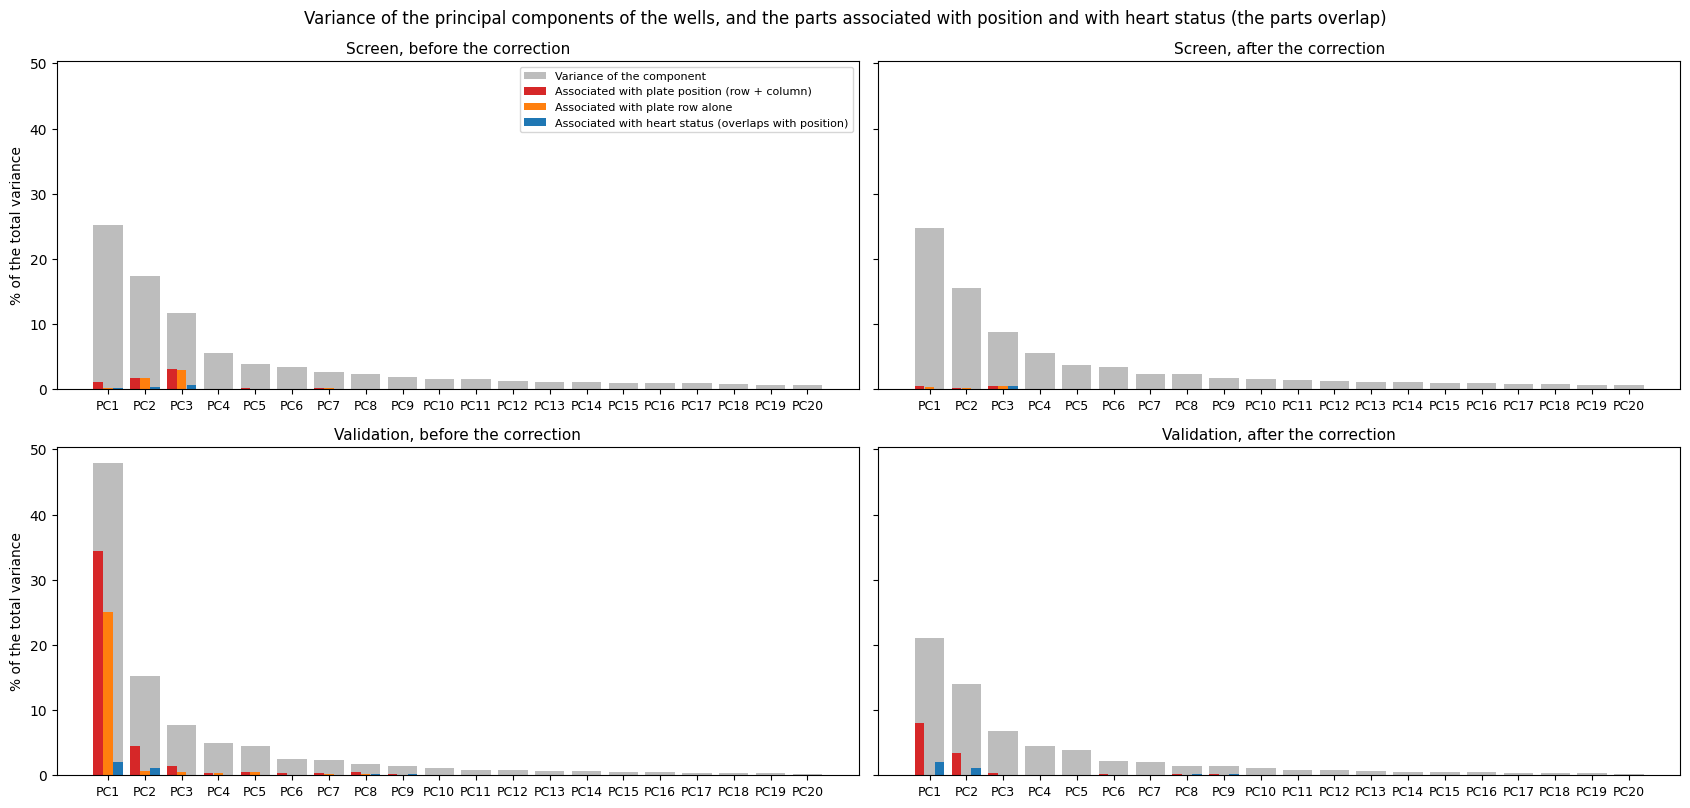

In [4]:
fig, axes = plt.subplots(len(datasets), 2, figsize=(17, 8.2), sharey=True)
for i, (name, table) in enumerate(partitions.items()):
    for j, stage in enumerate(("before", "after")):
        ax = axes[i, j]
        subset = table[table["stage"] == stage]
        x = np.arange(len(subset))
        ax.bar(x, subset["variance_pct_of_total"], width=0.8, color=colors["total"], label="Variance of the component")
        ax.bar(x - 0.27, subset["position_pct_of_total"], width=0.26, color=colors["position"], label="Associated with plate position (row + column)")
        ax.bar(x, subset["row_pct_of_total"], width=0.26, color="#ff7f0e", label="Associated with plate row alone")
        ax.bar(x + 0.27, subset["status_pct_of_total"], width=0.26, color=colors["status"], label="Associated with heart status (overlaps with position)")
        ax.set_xticks(x)
        ax.set_xticklabels(subset["component"], fontsize=9)
        ax.set_title(f"{name}, {'before' if stage == 'before' else 'after'} the correction", fontsize=11)
        if j == 0:
            ax.set_ylabel("% of the total variance")
axes[0, 0].legend(fontsize=8, loc="upper right")
fig.suptitle("Variance of the principal components of the wells, and the parts associated with position and with heart status (the parts overlap)", fontsize=12)
fig.tight_layout()
fig.savefig(figure_dir / "scree_position_and_heart_status.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Survival of the non-failing against failing difference

For every plate, the length of the difference between the mean non-failing DMSO profile and the mean failing DMSO profile (over all features, in standard deviations of a single cell), before and after the correction.
On the screen, the non-failing controls are in row B and the failing controls in row E on every platemap, so the correction shifts the two controls differently.
On the validation plates both cell types sit in every row, at the same positions on every plate, so the tilt shifts the two controls alike and leaves their difference as it is.
The difference that survives is the one that is left after the fitted tilt is subtracted. It is not necessarily all biology: the fit leaves the offsets of the three blocks of columns in the group effects.

In [5]:
survival = {
    name: pce.nonfailing_failing_difference(data["medians"], data["fit"], data["nonfailing"])
    for name, data in datasets.items()
}
# a plate that has no non-failing or no failing DMSO well with enough cells has no difference
for name, table in survival.items():
    excluded = table[table["raw"].isna()]
    print(f"{name}: {len(table) - len(excluded)} of {len(table)} plates have both DMSO groups")
    for row in excluded.itertuples():
        print(f"  excluded {row.plate}: {row.n_nonfailing_dmso_wells} non-failing and {row.n_failing_dmso_wells} failing DMSO wells")
print(pd.DataFrame({name: table[["raw", "corrected", "share_that_survives"]].median() for name, table in survival.items()}).round(2).to_string())

Screen: 43 of 44 plates have both DMSO groups
  excluded CARD-CelIns-CX7_260115110001: 0 non-failing and 1 failing DMSO wells
Validation: 5 of 5 plates have both DMSO groups
                     Screen  Validation
raw                   19.52       12.97
corrected             18.47       12.97
share_that_survives    0.84        1.00


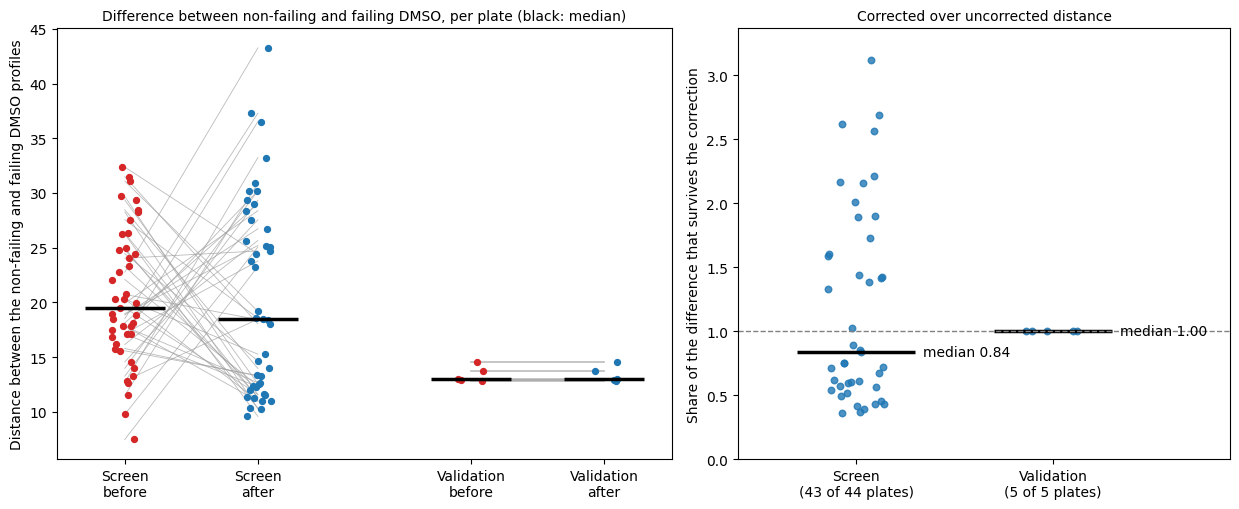

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
rng = np.random.default_rng(seed)
positions = {"Screen": (0, 1), "Validation": (2.6, 3.6)}
for name, table in survival.items():
    left, right = positions[name]
    for _, plate in table.iterrows():
        ax.plot([left, right], [plate["raw"], plate["corrected"]], color="#9e9e9e", lw=0.6 if name == "Screen" else 1.2, alpha=0.7)
    ax.scatter(np.full(len(table), left) + rng.uniform(-0.1, 0.1, len(table)), table["raw"], s=18, color=colors["position"], zorder=3)
    ax.scatter(np.full(len(table), right) + rng.uniform(-0.1, 0.1, len(table)), table["corrected"], s=18, color=colors["status"], zorder=3)
    ax.hlines([table["raw"].median(), table["corrected"].median()], [left - 0.3, right - 0.3], [left + 0.3, right + 0.3], color="black", lw=2.5, zorder=4)
ax.set_xticks([0, 1, 2.6, 3.6])
ax.set_xticklabels(["Screen\nbefore", "Screen\nafter", "Validation\nbefore", "Validation\nafter"])
ax.set_ylabel("Distance between the non-failing and failing DMSO profiles")
ax.set_title("Difference between non-failing and failing DMSO, per plate (black: median)", fontsize=10)
ax = axes[1]
for k, (name, table) in enumerate(survival.items()):
    ax.scatter(np.full(len(table), k) + rng.uniform(-0.15, 0.15, len(table)), table["share_that_survives"], s=22, color=colors["status"], alpha=0.8)
    median = table["share_that_survives"].median()
    ax.hlines(median, k - 0.3, k + 0.3, color="black", lw=2.5)
    ax.text(k + 0.34, median, f"median {median:.2f}", va="center", fontsize=10)
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xlim(-0.6, 1.9)
top = max(1.15, 1.08 * max(table["share_that_survives"].max() for table in survival.values()))
ax.set_ylim(0, top)
ax.set_xticks([0, 1])
ax.set_xticklabels([f"{name}\n({table['raw'].notna().sum()} of {len(table)} plates)" for name, table in survival.items()])
ax.set_ylabel("Share of the difference that survives the correction")
ax.set_title("Corrected over uncorrected distance", fontsize=10)
fig.tight_layout()
fig.savefig(figure_dir / "nonfailing_failing_survival.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Compound placement in the screen

The tilt of the screen, and its use in the rescue score, assume that compounds were placed on the plates independently of the position.
Each screen compound sits at one position of its platemap, so the assumption cannot be tested within a compound.
We test two things: whether the compound classes (pathways) differ by plate row within the platemaps (a permutation test that shuffles the pathways within each platemap), and whether the compound identifier (a running number) follows the order of the wells on a platemap.
The controls (`DMSO` and `TGFRi`) are not compounds and are left out of both tests.

In [7]:
frames = []
for path in sorted(platemap_dir.glob("*_with_pathways.csv")):
    frame = pd.read_csv(path)
    frame["platemap"] = int(path.name.split("Plate_")[1].split("_")[0])
    frames.append(frame)
platemaps = pd.concat(frames, ignore_index=True)
screen_compounds = platemaps[~platemaps["treatment"].isin(pcu.CONTROL_TREATMENTS) & platemaps["treatment"].notna()].copy()
screen_compounds["row_index"] = screen_compounds["well_position"].str[0].map({row: i for i, row in enumerate("BCDEFG")})
screen_compounds["column"] = screen_compounds["well_position"].str[1:].astype(int)
screen_compounds["reading_order"] = screen_compounds["row_index"] * 10 + screen_compounds["column"]
screen_compounds["compound_number"] = screen_compounds["treatment"].str.extract(r"(\d+)")[0].astype(float)

# the pathway against the plate row within each platemap (the platemaps are not pooled), with the
# pathway labels permuted within each platemap
statistic, p_pathway = pce.within_map_association_test(
    screen_compounds["platemap"], screen_compounds["Pathway"].fillna("none"), screen_compounds["well_position"].str[0]
)
print(
    f"Pathway against plate row within platemaps: statistic {statistic:.0f}, permutation p = {p_pathway:.3f} "
    f"({len(screen_compounds)} compounds, {screen_compounds['Pathway'].nunique()} pathways)"
)

placement = []
for platemap, group in screen_compounds.groupby("platemap"):
    result = spearmanr(group["compound_number"], group["reading_order"], nan_policy="omit")
    placement.append({"platemap": platemap, "n_compounds": len(group), "spearman_rho": result.statistic, "p_value": result.pvalue})
placement = pd.DataFrame(placement)
print(placement.round(3).to_string(index=False))

Pathway against plate row within platemaps: statistic 868, permutation p = 0.663 (550 compounds, 23 pathways)
 platemap  n_compounds  spearman_rho  p_value
        1           52         0.076    0.594
        2           52         0.140    0.324
        3           52         0.133    0.348
        4           52         0.235    0.093
        5           52         0.540    0.000
        6           52         0.102    0.471
        7           52         0.489    0.000
        8           52         0.707    0.000
        9           52         0.045    0.749
       10           52         0.565    0.000
       11           30         0.212    0.262


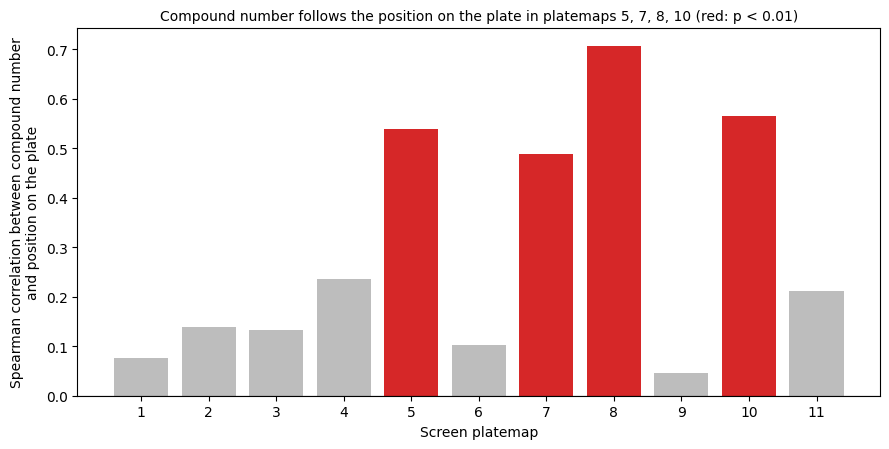

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.6))
order = placement.sort_values("platemap")
bar_colors = [colors["position"] if p < 0.01 else "#bdbdbd" for p in order["p_value"]]
ax.bar(order["platemap"].astype(str), order["spearman_rho"], color=bar_colors)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Screen platemap")
ax.set_ylabel("Spearman correlation between compound number\nand position on the plate")
significant = order.loc[order["p_value"] < 0.01, "platemap"].astype(str).tolist()
ax.set_title(
    f"Compound number follows the position on the plate in platemaps {', '.join(significant)} (red: p < 0.01)"
    if significant
    else "Compound number does not follow the position on any platemap (red: p < 0.01)",
    fontsize=10,
)
fig.tight_layout()
fig.savefig(figure_dir / "screen_compound_placement.png", dpi=150, bbox_inches="tight")
plt.show()